Total Accounts Analyzed: 7,043 | Overall Churn Rate: 26.5%

--- PATH 1: NORMAL SQL/EXCEL RULE BASELINE ---
Accuracy: 75.3% | Churners Caught (Recall): 54.8% | Annual At-Risk Revenue Caught: EUR 156,355.80

--- PATH 2: RANDOM FOREST ML CLASSIFIER ---
Accuracy: 80.3% | Churners Caught (Recall): 50.0% | ROC-AUC: 0.845 | Annual At-Risk Revenue Caught: EUR 171,194.40

Exported 159 high-risk accounts (>=60% risk) to High_Risk_Retention_List.csv


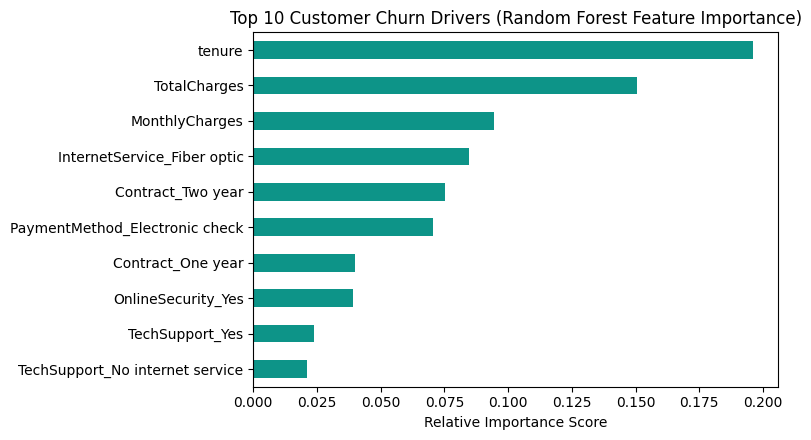

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, roc_auc_score

# 1. Load & Clean Data
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)
df['Annual_Revenue_EUR'] = (df['MonthlyCharges'] * 12).round(2)
y = df['Churn'].map({'Yes': 1, 'No': 0})

print(f"Total Accounts Analyzed: {len(df):,} | Overall Churn Rate: {y.mean():.1%}\n")

# 2. Train / Test Split (80% Train, 20% Holdout Test)
X = pd.get_dummies(df.drop(columns=['customerID', 'Churn', 'Annual_Revenue_EUR']), drop_first=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
test_df = df.loc[X_test.index].copy()

# ==========================================================
# PATH 1: NORMAL SQL / EXCEL BUSINESS RULE BASELINE
# Rule: Flag Month-to-Month customers with tenure < 12 months
# ==========================================================
rule_pred = ((test_df['Contract'] == 'Month-to-month') & (test_df['tenure'] < 12)).astype(int)
rule_acc = accuracy_score(y_test, rule_pred)
rule_rec = recall_score(y_test, rule_pred)
rule_rev = test_df.loc[(rule_pred == 1) & (y_test == 1), 'Annual_Revenue_EUR'].sum()

print("--- PATH 1: NORMAL SQL/EXCEL RULE BASELINE ---")
print(f"Accuracy: {rule_acc:.1%} | Churners Caught (Recall): {rule_rec:.1%} | Annual At-Risk Revenue Caught: EUR {rule_rev:,.2f}\n")

# ==========================================================
# PATH 2: MACHINE LEARNING UPGRADE (RANDOM FOREST)
# ==========================================================
rf = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)
rf.fit(X_train, y_train)

ml_pred = rf.predict(X_test)
ml_prob = rf.predict_proba(X_test)[:, 1]
ml_acc = accuracy_score(y_test, ml_pred)
ml_rec = recall_score(y_test, ml_pred)
ml_auc = roc_auc_score(y_test, ml_prob)
ml_rev = test_df.loc[(ml_pred == 1) & (y_test == 1), 'Annual_Revenue_EUR'].sum()

print("--- PATH 2: RANDOM FOREST ML CLASSIFIER ---")
print(f"Accuracy: {ml_acc:.1%} | Churners Caught (Recall): {ml_rec:.1%} | ROC-AUC: {ml_auc:.3f} | Annual At-Risk Revenue Caught: EUR {ml_rev:,.2f}\n")

# 3. Export Actionable High-Risk Retention List for Account Managers
out = test_df[['customerID', 'tenure', 'Contract', 'MonthlyCharges', 'Annual_Revenue_EUR']].copy()
out['Churn_Risk_Pct'] = (ml_prob * 100).round(1)
high_risk = out[out['Churn_Risk_Pct'] >= 60].sort_values('Annual_Revenue_EUR', ascending=False)
high_risk.to_csv('High_Risk_Retention_List.csv', index=False)
print(f"Exported {len(high_risk)} high-risk accounts (>=60% risk) to High_Risk_Retention_List.csv")

# 4. Plot & Save Top 10 Churn Drivers Chart
feat_imp = pd.Series(rf.feature_importances_, index=X.columns).nlargest(10).sort_values()
plt.figure(figsize=(8, 4.5))
feat_imp.plot(kind='barh', color='#0D9488')
plt.title('Top 10 Customer Churn Drivers (Random Forest Feature Importance)')
plt.xlabel('Relative Importance Score')
plt.tight_layout()
plt.savefig('churn_drivers_chart.png', dpi=300)
plt.show()